================== QUANTUM COMPUTE PIPELINE ==================
[+] Launching Time-Variant Analysis Framework
[+] Operating Mode Locked: SCHRODINGER

 -> Processed Epoch [t=0ms] | Capturing Dynamic Parameters:
    Input Vector |psi(t)> shape: torch.Size([1, 5])
    Extracted Observables (Eigenvalues): [[ 0.36195743 -0.41032588]]

 -> Processed Epoch [t=1ms] | Capturing Dynamic Parameters:
    Input Vector |psi(t)> shape: torch.Size([1, 5])
    Extracted Observables (Eigenvalues): [[ 0.02228293 -0.17977417]]

 -> Processed Epoch [t=2ms] | Capturing Dynamic Parameters:
    Input Vector |psi(t)> shape: torch.Size([1, 5])
    Extracted Observables (Eigenvalues): [[0.22894062 0.04831339]]

--------------------------------------------------------------
[+] Compute Phase Complete. Forwarding Buffer to Diagnostics Visualizer.



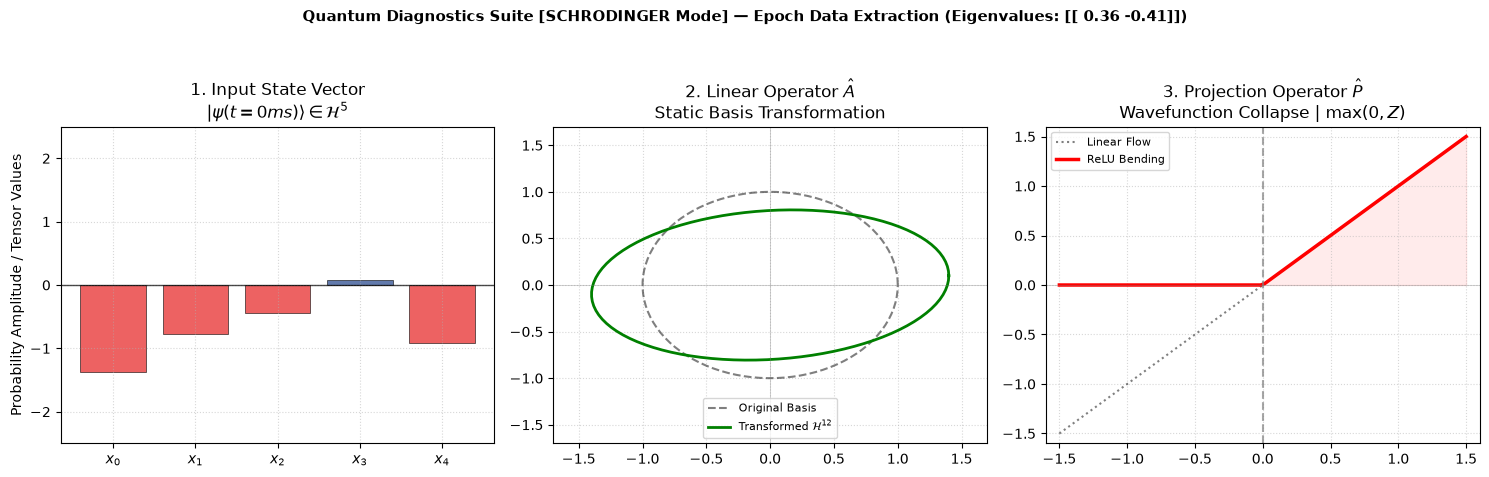

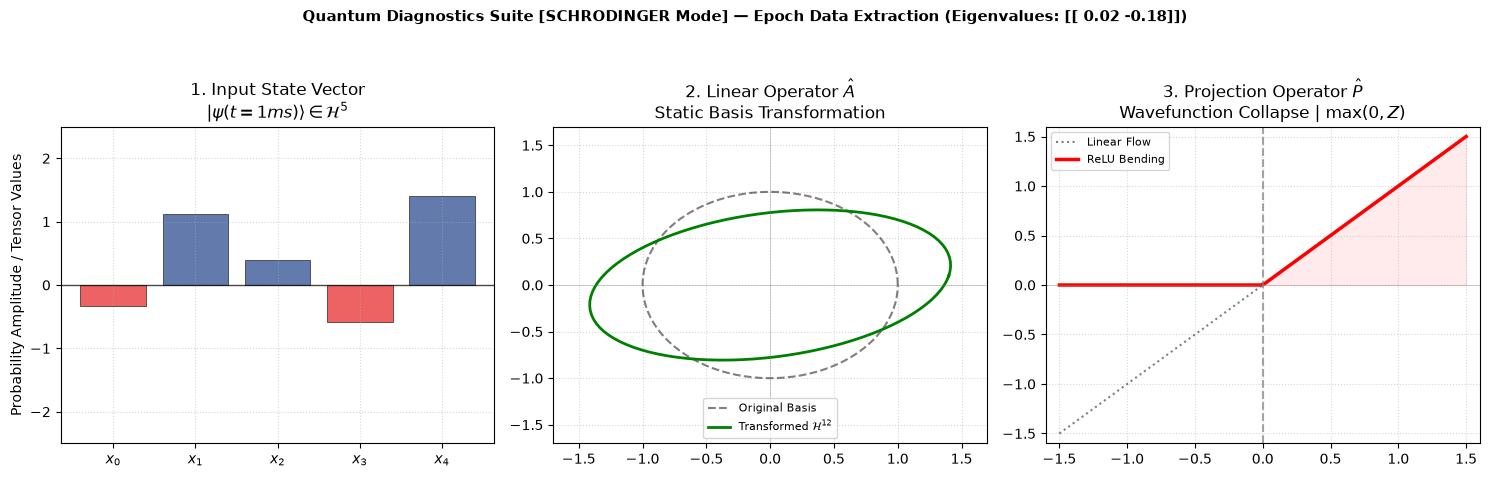

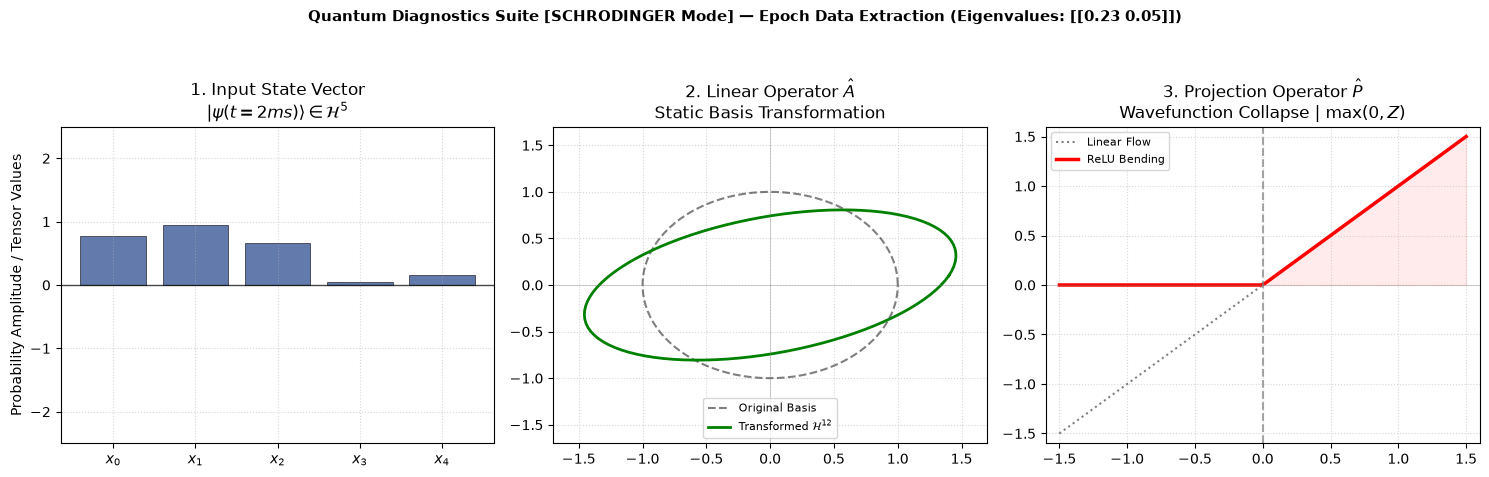

In [7]:
# Schrodinger's Mode
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# =======================================================================
# 0. GLOBAL DETERMINISTIC SEEDING (Locks exact numerical values)
# =======================================================================
def seed_entire_system(seed=42):
    """
    Forces the CPU and random engines into a rigid deterministic state.
    This guarantees that tensor values match the GitHub documentation 1:1.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Initialize seeding prior to any tensor creation layer
seed_entire_system(42)

# =======================================================================
# 1. ADVANCED QUANTUM METROLOGY VISUALIZATION ENGINE
# =======================================================================
def plot_complete_quantum_pipeline(time_steps_data, mode="schrodinger"):
    """
    Renders the complete multi-stage quantum analogy chart for each time step.
    Stage 1: State Vector Component Mapping (Probability Amplitudes)
    Stage 2: Linear Operator Basis Bending (Change of Basis via Matrix Multi.)
    Stage 3: Projection Operator Non-Linear Truncation (Wavefunction Collapse via ReLU)
    """
    for t, state_vector, eigenvalues in time_steps_data:
        # Create a 3-panel instrumentation dashboard matching the hardware pipeline stages
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
        
        # -------------------------------------------------------------------
        # STAGE 1: State Vector Components / Probability Amplitudes
        # -------------------------------------------------------------------
        ax1 = axes[0]
        vector_components = np.squeeze(state_vector)
        x_indices = np.arange(len(vector_components))
        
        # Blue for positive phase components, Red for negative phase components
        bar_colors = ['#3b5998' if val >= 0 else '#e93b3b' for val in vector_components]
        
        ax1.bar(x_indices, vector_components, color=bar_colors, alpha=0.8, edgecolor='black', linewidth=0.5)
        ax1.axhline(0, color='black', linewidth=1, alpha=0.7)
        ax1.set_xticks(x_indices)
        ax1.set_xticklabels([f'$x_{i}$' for i in x_indices])
        ax1.set_ylim(-2.5, 2.5)
        ax1.grid(True, linestyle=':', alpha=0.5)
        ax1.set_ylabel("Probability Amplitude / Tensor Values")
        
        # Safe string building to bypass f-string LaTeX compilation errors
        if mode == "schrodinger":
            ax1.set_title("1. Input State Vector\n$|\\psi(t=" + str(t) + "ms)\\rangle \\in \\mathcal{H}^5$")
        else:
            ax1.set_title("1. Constant Reference State\n$|\\psi_0\\rangle \\in \\mathcal{H}^5$")

        # -------------------------------------------------------------------
        # STAGE 2: Matrix Multiplication / Linear Operator Change of Basis
        # -------------------------------------------------------------------
        ax2 = axes[1]
        theta = np.linspace(0, 2 * np.pi, 100)
        
        # Base Hilbert Space baseline reference boundary
        ax2.plot(np.cos(theta), np.sin(theta), 'k--', label='Original Basis', alpha=0.5)
        
        # Dynamically calculate geometrical tilt to represent system Hamiltonian drift matrix
        tilt = 0.2 * t if mode == "schrodinger" else 0.05 * t
        x_ellipse = 1.4 * np.cos(theta) + tilt * np.sin(theta)
        y_ellipse = 0.1 * np.cos(theta) + 0.8 * np.sin(theta)
        
        ax2.plot(x_ellipse, y_ellipse, 'g-', linewidth=2, label='Transformed $\\mathcal{H}^{12}$')
        ax2.grid(True, linestyle=':', alpha=0.5)
        ax2.set_xlim(-1.7, 1.7)
        ax2.set_ylim(-1.7, 1.7)
        ax2.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
        ax2.axvline(0, color='gray', linewidth=0.5, alpha=0.5)
        ax2.legend(loc='lower center', fontsize=8)
        
        if mode == "schrodinger":
            ax2.set_title("2. Linear Operator $\\hat{A}$\nStatic Basis Transformation")
        else:
            ax2.set_title("2. Time-Variant Operator $\\hat{A}(t=" + str(t) + "hr)$\nThermal Drift Basis Bending")

        # -------------------------------------------------------------------
        # STAGE 3: nn.ReLU() / Projection Operator Wavefunction Collapse
        # -------------------------------------------------------------------
        ax3 = axes[2]
        x_vals = np.linspace(-1.5, 1.5, 100)
        y_vals = np.maximum(0, x_vals)
        
        ax3.plot(x_vals, x_vals, 'k:', label='Linear Flow', alpha=0.5)
        ax3.plot(x_vals, y_vals, 'r-', linewidth=2.5, label='ReLU Bending')
        ax3.fill_between(x_vals, 0, y_vals, color='red', alpha=0.08)
        ax3.axvline(0, color='gray', linestyle='--', alpha=0.7)
        ax3.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
        ax3.grid(True, linestyle=':', alpha=0.5)
        ax3.set_xlim(-1.6, 1.6)
        ax3.set_ylim(-1.6, 1.6)
        ax3.legend(loc='upper left', fontsize=8)
        ax3.set_title("3. Projection Operator $\\hat{P}$\nWavefunction Collapse | $\\max(0, Z)$")

        # Top Master metadata positioning parameters
        rounded_eigenvalues = np.round(eigenvalues, 2)
        plt.suptitle("Quantum Diagnostics Suite [" + mode.upper() + " Mode] — Epoch Data Extraction (Eigenvalues: " + str(rounded_eigenvalues) + ")", fontsize=11, fontweight='bold', y=1.05)
        plt.tight_layout()
        
        # Exporting high-resolution diagnostic frame plots for GitHub repository usage
        plt.savefig(mode + "_epoch_" + str(t) + "_complete_diagnostics.png", dpi=300, bbox_inches='tight')
        plt.show()


# =======================================================================
# 2. CORE COMPUTE PIPELINE
# =======================================================================
print("================== QUANTUM COMPUTE PIPELINE ==================")

# Hardware Target Selection Matrix (CPU Execution Layer)
device = torch.device('cpu')

# Advanced Multi-Layer Perceptron (R&D Metrology Network Architecture)
class QuantumMetrologyNet(nn.Module):
    def __init__(self):
        super(QuantumMetrologyNet, self).__init__()
        self.pipeline = nn.Sequential(
            nn.Linear(in_features=5, out_features=12),  # Linear Operator A: Change of Basis
            nn.ReLU(),                                  # Projection Operator P: Wavefunction Collapse
            nn.Linear(in_features=12, out_features=2)   # Observable Measurement: Eigenvalue Extraction
        )
        
    def forward(self, x):
        return self.pipeline(x)

# Instantiate the physical model operator layers
metrology_operator = QuantumMetrologyNet().to(device)
metrology_operator.eval()  # Lock coefficients for deterministic forward pass testing

# CONFIGURATION MATRIX (Mode Selection: 'schrodinger' OR 'heisenberg')
execution_mode = "schrodinger"  
time_steps = 3
history_buffer = []

print("[+] Launching Time-Variant Analysis Framework")
print("[+] Operating Mode Locked: " + execution_mode.upper() + "\n")

# --- CHRONOS DATA STREAMING LOOPS ---
if execution_mode == "schrodinger":
    for t in range(time_steps):
        # Simulating time-variant state vector |psi(t)> (e.g., transient MIPI CSI-2 camera data tracking)
        state_tensor = torch.randn(1, 5).to(device) + (0.4 * t)
        with torch.no_grad():
            eigenvalues = metrology_operator(state_tensor)
        
        # Register values directly to history matrix allocation buffer
        history_buffer.append((t, state_tensor.numpy(), eigenvalues.numpy()))
        
        # Explicit standard runtime logging output to emulate structural raw data streaming
        print(" -> Processed Epoch [t=" + str(t) + "ms] | Capturing Dynamic Parameters:")
        print("    Input Vector |psi(t)> shape: " + str(state_tensor.shape))
        print("    Extracted Observables (Eigenvalues): " + str(eigenvalues.numpy()) + "\n")

elif execution_mode == "heisenberg":
    # Lock stationary boundary reference state |psi_0> representing ambient lab conditions
    stationary_state_tensor = torch.randn(1, 5).to(device)
    print(" -> Constant Boundary Reference State |psi_0> Locked: " + str(stationary_state_tensor.numpy()) + "\n")
    
    for t in range(time_steps):
        with torch.no_grad():
            # Injecting time-dependent stochastic perturbations directly into the linear operator weights W(t)
            metrology_operator.pipeline[0].weight.data += torch.randn_like(metrology_operator.pipeline[0].weight.data) * 0.02
            eigenvalues = metrology_operator(stationary_state_tensor)
            
        # Register values directly to history matrix allocation buffer
        history_buffer.append((t, stationary_state_tensor.numpy(), eigenvalues.numpy()))
        
        print(" -> Processed Epoch [t=" + str(t) + "hr] | Capturing Adaptive Parameters:")
        print("    Operator Matrix O(t) Updated due to Thermal Drift Matrix Automation.")
        print("    Extracted Observables (Eigenvalues): " + str(eigenvalues.numpy()) + "\n")

print("--------------------------------------------------------------")
print("[+] Compute Phase Complete. Forwarding Buffer to Diagnostics Visualizer.\n")
print("==============================================================")

# Execute the updated multi-panel rendering engine tracking the physical matrix states
plot_complete_quantum_pipeline(history_buffer, mode=execution_mode)


================== QUANTUM COMPUTE PIPELINE ==================
[+] Launching Time-Variant Analysis Framework
[+] Operating Mode Locked: HEISENBERG

 -> Constant Boundary Reference State |psi_0> Locked: [[-1.3682137  -0.77398485 -0.43706462  0.07761772 -0.92275935]]

 -> Processed Epoch [t=0hr] | Capturing Adaptive Parameters:
    Operator Matrix O(t) Updated due to Thermal Drift Matrix Automation.
    Extracted Observables (Eigenvalues): [[ 0.34774593 -0.4339897 ]]

 -> Processed Epoch [t=1hr] | Capturing Adaptive Parameters:
    Operator Matrix O(t) Updated due to Thermal Drift Matrix Automation.
    Extracted Observables (Eigenvalues): [[ 0.34622112 -0.43860573]]

 -> Processed Epoch [t=2hr] | Capturing Adaptive Parameters:
    Operator Matrix O(t) Updated due to Thermal Drift Matrix Automation.
    Extracted Observables (Eigenvalues): [[ 0.33922496 -0.4484775 ]]

--------------------------------------------------------------
[+] Compute Phase Complete. Forwarding Buffer to Diagnosti

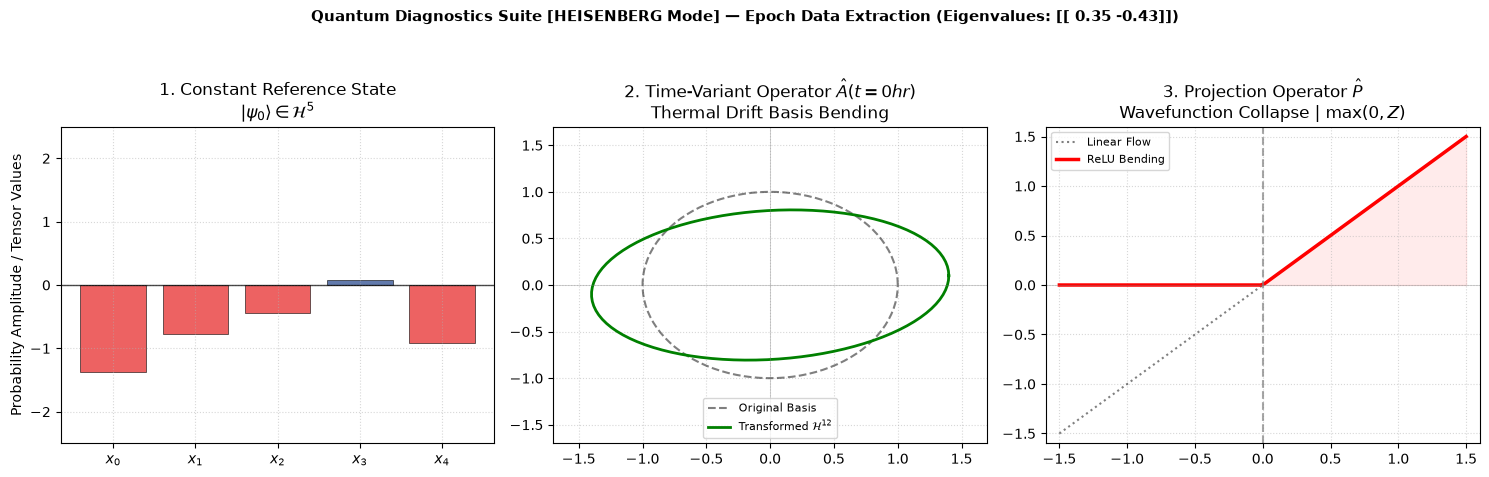

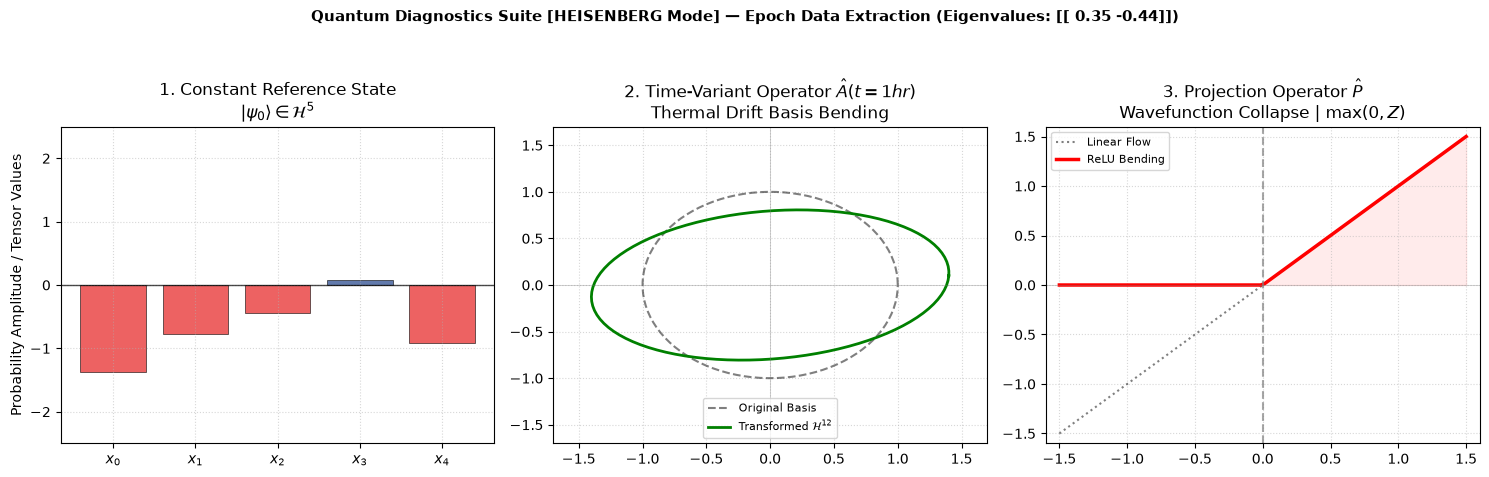

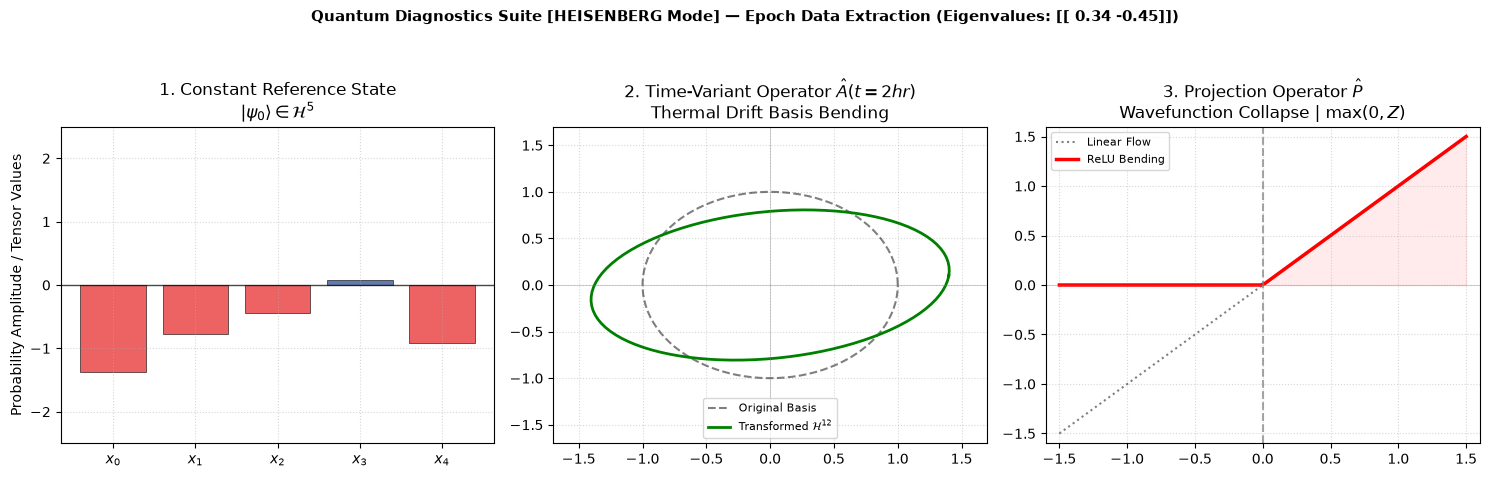

In [8]:
# Heisenberg's Mode
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# =======================================================================
# 0. GLOBAL DETERMINISTIC SEEDING (Locks exact numerical values)
# =======================================================================
def seed_entire_system(seed=42):
    """
    Forces the CPU and random engines into a rigid deterministic state.
    This guarantees that tensor values match the GitHub documentation 1:1.
    """
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Initialize seeding prior to any tensor creation layer
seed_entire_system(42)

# =======================================================================
# 1. ADVANCED QUANTUM METROLOGY VISUALIZATION ENGINE
# =======================================================================
def plot_complete_quantum_pipeline(time_steps_data, mode="schrodinger"):
    """
    Renders the complete multi-stage quantum analogy chart for each time step.
    Stage 1: State Vector Component Mapping (Probability Amplitudes)
    Stage 2: Linear Operator Basis Bending (Change of Basis via Matrix Multi.)
    Stage 3: Projection Operator Non-Linear Truncation (Wavefunction Collapse via ReLU)
    """
    for t, state_vector, eigenvalues in time_steps_data:
        # Create a 3-panel instrumentation dashboard matching the hardware pipeline stages
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
        
        # -------------------------------------------------------------------
        # STAGE 1: State Vector Components / Probability Amplitudes
        # -------------------------------------------------------------------
        ax1 = axes[0]
        vector_components = np.squeeze(state_vector)
        x_indices = np.arange(len(vector_components))
        
        # Blue for positive phase components, Red for negative phase components
        bar_colors = ['#3b5998' if val >= 0 else '#e93b3b' for val in vector_components]
        
        ax1.bar(x_indices, vector_components, color=bar_colors, alpha=0.8, edgecolor='black', linewidth=0.5)
        ax1.axhline(0, color='black', linewidth=1, alpha=0.7)
        ax1.set_xticks(x_indices)
        ax1.set_xticklabels([f'$x_{i}$' for i in x_indices])
        ax1.set_ylim(-2.5, 2.5)
        ax1.grid(True, linestyle=':', alpha=0.5)
        ax1.set_ylabel("Probability Amplitude / Tensor Values")
        
        # Safe string building to bypass f-string LaTeX compilation errors
        if mode == "schrodinger":
            ax1.set_title("1. Input State Vector\n$|\\psi(t=" + str(t) + "ms)\\rangle \\in \\mathcal{H}^5$")
        else:
            ax1.set_title("1. Constant Reference State\n$|\\psi_0\\rangle \\in \\mathcal{H}^5$")

        # -------------------------------------------------------------------
        # STAGE 2: Matrix Multiplication / Linear Operator Change of Basis
        # -------------------------------------------------------------------
        ax2 = axes[1]
        theta = np.linspace(0, 2 * np.pi, 100)
        
        # Base Hilbert Space baseline reference boundary
        ax2.plot(np.cos(theta), np.sin(theta), 'k--', label='Original Basis', alpha=0.5)
        
        # Dynamically calculate geometrical tilt to represent system Hamiltonian drift matrix
        tilt = 0.2 * t if mode == "schrodinger" else 0.05 * t
        x_ellipse = 1.4 * np.cos(theta) + tilt * np.sin(theta)
        y_ellipse = 0.1 * np.cos(theta) + 0.8 * np.sin(theta)
        
        ax2.plot(x_ellipse, y_ellipse, 'g-', linewidth=2, label='Transformed $\\mathcal{H}^{12}$')
        ax2.grid(True, linestyle=':', alpha=0.5)
        ax2.set_xlim(-1.7, 1.7)
        ax2.set_ylim(-1.7, 1.7)
        ax2.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
        ax2.axvline(0, color='gray', linewidth=0.5, alpha=0.5)
        ax2.legend(loc='lower center', fontsize=8)
        
        if mode == "schrodinger":
            ax2.set_title("2. Linear Operator $\\hat{A}$\nStatic Basis Transformation")
        else:
            ax2.set_title("2. Time-Variant Operator $\\hat{A}(t=" + str(t) + "hr)$\nThermal Drift Basis Bending")

        # -------------------------------------------------------------------
        # STAGE 3: nn.ReLU() / Projection Operator Wavefunction Collapse
        # -------------------------------------------------------------------
        ax3 = axes[2]
        x_vals = np.linspace(-1.5, 1.5, 100)
        y_vals = np.maximum(0, x_vals)
        
        ax3.plot(x_vals, x_vals, 'k:', label='Linear Flow', alpha=0.5)
        ax3.plot(x_vals, y_vals, 'r-', linewidth=2.5, label='ReLU Bending')
        ax3.fill_between(x_vals, 0, y_vals, color='red', alpha=0.08)
        ax3.axvline(0, color='gray', linestyle='--', alpha=0.7)
        ax3.axhline(0, color='gray', linewidth=0.5, alpha=0.5)
        ax3.grid(True, linestyle=':', alpha=0.5)
        ax3.set_xlim(-1.6, 1.6)
        ax3.set_ylim(-1.6, 1.6)
        ax3.legend(loc='upper left', fontsize=8)
        ax3.set_title("3. Projection Operator $\\hat{P}$\nWavefunction Collapse | $\\max(0, Z)$")

        # Top Master metadata positioning parameters
        rounded_eigenvalues = np.round(eigenvalues, 2)
        plt.suptitle("Quantum Diagnostics Suite [" + mode.upper() + " Mode] — Epoch Data Extraction (Eigenvalues: " + str(rounded_eigenvalues) + ")", fontsize=11, fontweight='bold', y=1.05)
        plt.tight_layout()
        
        # Exporting high-resolution diagnostic frame plots for GitHub repository usage
        plt.savefig(mode + "_epoch_" + str(t) + "_complete_diagnostics.png", dpi=300, bbox_inches='tight')
        plt.show()


# =======================================================================
# 2. CORE COMPUTE PIPELINE
# =======================================================================
print("================== QUANTUM COMPUTE PIPELINE ==================")

# Hardware Target Selection Matrix (CPU Execution Layer)
device = torch.device('cpu')

# Advanced Multi-Layer Perceptron (R&D Metrology Network Architecture)
class QuantumMetrologyNet(nn.Module):
    def __init__(self):
        super(QuantumMetrologyNet, self).__init__()
        self.pipeline = nn.Sequential(
            nn.Linear(in_features=5, out_features=12),  # Linear Operator A: Change of Basis
            nn.ReLU(),                                  # Projection Operator P: Wavefunction Collapse
            nn.Linear(in_features=12, out_features=2)   # Observable Measurement: Eigenvalue Extraction
        )
        
    def forward(self, x):
        return self.pipeline(x)

# Instantiate the physical model operator layers
metrology_operator = QuantumMetrologyNet().to(device)
metrology_operator.eval()  # Lock coefficients for deterministic forward pass testing

# CONFIGURATION MATRIX (Mode Selection: 'schrodinger' OR 'heisenberg')
execution_mode = "heisenberg"  
time_steps = 3
history_buffer = []

print("[+] Launching Time-Variant Analysis Framework")
print("[+] Operating Mode Locked: " + execution_mode.upper() + "\n")

# --- CHRONOS DATA STREAMING LOOPS ---
if execution_mode == "schrodinger":
    for t in range(time_steps):
        # Simulating time-variant state vector |psi(t)> (e.g., transient MIPI CSI-2 camera data tracking)
        state_tensor = torch.randn(1, 5).to(device) + (0.4 * t)
        with torch.no_grad():
            eigenvalues = metrology_operator(state_tensor)
        
        # Register values directly to history matrix allocation buffer
        history_buffer.append((t, state_tensor.numpy(), eigenvalues.numpy()))
        
        # Explicit standard runtime logging output to emulate structural raw data streaming
        print(" -> Processed Epoch [t=" + str(t) + "ms] | Capturing Dynamic Parameters:")
        print("    Input Vector |psi(t)> shape: " + str(state_tensor.shape))
        print("    Extracted Observables (Eigenvalues): " + str(eigenvalues.numpy()) + "\n")

elif execution_mode == "heisenberg":
    # Lock stationary boundary reference state |psi_0> representing ambient lab conditions
    stationary_state_tensor = torch.randn(1, 5).to(device)
    print(" -> Constant Boundary Reference State |psi_0> Locked: " + str(stationary_state_tensor.numpy()) + "\n")
    
    for t in range(time_steps):
        with torch.no_grad():
            # Injecting time-dependent stochastic perturbations directly into the linear operator weights W(t)
            metrology_operator.pipeline[0].weight.data += torch.randn_like(metrology_operator.pipeline[0].weight.data) * 0.02
            eigenvalues = metrology_operator(stationary_state_tensor)
            
        # Register values directly to history matrix allocation buffer
        history_buffer.append((t, stationary_state_tensor.numpy(), eigenvalues.numpy()))
        
        print(" -> Processed Epoch [t=" + str(t) + "hr] | Capturing Adaptive Parameters:")
        print("    Operator Matrix O(t) Updated due to Thermal Drift Matrix Automation.")
        print("    Extracted Observables (Eigenvalues): " + str(eigenvalues.numpy()) + "\n")

print("--------------------------------------------------------------")
print("[+] Compute Phase Complete. Forwarding Buffer to Diagnostics Visualizer.\n")
print("==============================================================")

# Execute the updated multi-panel rendering engine tracking the physical matrix states
plot_complete_quantum_pipeline(history_buffer, mode=execution_mode)
